# Лабораторная работа № 3. Трансформация и визуализация данных

**ИТАиОД · Вариант 7**

Цель работы — построить сводные таблицы средствами `pivottabler`, оформить их для Excel и Word и представить результаты в `ggplot2`. Сравним форматы работы и профессиональный стаж участников опроса.

Источник варианта — [Stack Overflow Developer Survey 2011–2022 на Kaggle](https://www.kaggle.com/datasets/yasirabdaali/stack-overflow-developer-survey-20112022). В анализе используется срез **2022 года**. В этом выпуске есть отдельный вопрос о формате работы `RemoteWork`. Для воспроизведения распакуйте CSV 2022 года как `../data/survey_results_public.csv` или укажите его путь переменной `ITAIOD_SURVEY_CSV`. После строки с идентификатором около 68 810 в копии CSV на Kaggle обнаружены посторонние двоичные данные. Для расчётов используется [оригинальный выпуск Stack Overflow](https://survey.stackoverflow.co/2022/). При отсутствии локального файла ноутбук загрузит официальный CSV во временный каталог.

Для запуска выберите ядро **R (IRkernel)**. Пакеты: `readr`, `dplyr`, `ggplot2`, `pivottabler`, `openxlsx`, `flextable`.

In [1]:
library(dplyr)
library(ggplot2)

# Прочитать выбранные поля выпуска 2022. Аргумент columns — имена столбцов.
# Результат — tibble с исходными строковыми значениями.
read_survey <- function(columns) {
  configured_file <- Sys.getenv("ITAIOD_SURVEY_CSV")
  candidates <- c(
    "../data/survey_results_public.csv",
    "survey_results_public.csv",
    "data/survey_results_public.csv",
    "итаиод/data/survey_results_public.csv"
  )

  if (nzchar(configured_file)) {
    if (!file.exists(configured_file)) {
      stop("Файл ITAIOD_SURVEY_CSV не найден: ", configured_file)
    }
    input <- configured_file
  } else if (any(file.exists(candidates))) {
    input <- candidates[file.exists(candidates)][1L]
  } else {
    input <- tempfile(fileext = ".csv")
    on.exit(unlink(input), add = TRUE)
    status <- download.file(
      "https://media.githubusercontent.com/media/StackExchange/Survey/main/packages/archive/2022/results.csv",
      input,
      mode = "wb"
    )
    if (status != 0L) {
      stop("Загрузите оригинальный выпуск 2022 года и задайте ITAIOD_SURVEY_CSV.")
    }
  }

  readr::read_csv(
    input,
    col_select = all_of(columns),
    col_types = readr::cols(.default = readr::col_character()),
    na = c("", "NA"),
    show_col_types = FALSE
  )
}

survey <- read_survey(c("ResponseId", "Country", "Employment", "RemoteWork", "YearsCodePro"))
head(survey, 4)


Attaching package: 'dplyr'




The following objects are masked from 'package:stats':

    filter, lag




The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




ResponseId,Country,Employment,RemoteWork,YearsCodePro
<chr>,<chr>,<chr>,<chr>,<chr>
1,NA,NA,NA,NA
2,Canada,"Employed, full-time",Fully remote,NA
3,United Kingdom of Great Britain and Northern Ireland,"Employed, full-time","Hybrid (some remote, some in-person)",5
4,Israel,"Employed, full-time",Fully remote,17


## 1. Подготовка данных

Режим работы сравнивается среди респондентов, указавших полную занятость. Поле `Employment` допускает несколько вариантов, поэтому полная занятость определяется по отдельной позиции списка. Ответы без страны или формата работы исключаются из сводки. Границы стажа «менее 1 года» и «более 50 лет» сохраняются как отдельные категории.

In [2]:
work_labels <- c(
  "Fully remote" = "Удалённый",
  "Hybrid (some remote, some in-person)" = "Гибридный",
  "Full in-person" = "Офисный"
)
work_colours <- c("Удалённый" = "#007C83", "Гибридный" = "#4263AB", "Офисный" = "#BC602B")

workers <- survey |>
  filter(grepl("(^|;)Employed, full-time(;|$)", Employment)) |>
  mutate(format = factor(unname(work_labels[RemoteWork]), levels = unname(work_labels))) |>
  filter(!is.na(ResponseId), !is.na(Country), !is.na(format)) |>
  distinct(ResponseId, .keep_all = TRUE)

stopifnot(nrow(workers) > 0L)

top_countries <- workers |>
  count(Country, name = "responses") |>
  arrange(desc(responses), Country) |>
  slice_head(n = 8L)

country_data <- workers |>
  filter(Country %in% top_countries$Country) |>
  mutate(country = factor(Country, levels = top_countries$Country))

experience_levels <- c("<1", "1–4", "5–9", "10–19", "20–50", ">50")
experience_data <- workers |>
  mutate(
    years = suppressWarnings(as.numeric(YearsCodePro)),
    experience = case_when(
      YearsCodePro == "Less than 1 year" ~ "<1",
      YearsCodePro == "More than 50 years" ~ ">50",
      years >= 1 & years < 5 ~ "1–4",
      years >= 5 & years < 10 ~ "5–9",
      years >= 10 & years < 20 ~ "10–19",
      years >= 20 & years <= 50 ~ "20–50"
    ),
    experience = factor(experience, levels = experience_levels)
  ) |>
  filter(!is.na(experience))

data.frame(
  all_responses = nrow(survey),
  valid_full_time = nrow(workers),
  top_countries = nrow(country_data),
  with_experience = nrow(experience_data)
)

all_responses,valid_full_time,top_countries,with_experience
<int>,<int>,<int>,<int>
73268,49188,27726,45566


## 2. Сводные таблицы

Для каждого сочетания страны и формата работы подсчитывается число респондентов. Во второй таблице аналогичный подсчёт выполняется по профессиональному стажу. Итоги по строкам и столбцам рассчитывает `pivottabler`. Строки данных подсчитываются после проверки уникальности `ResponseId`. Пустая ячейка означает, что в этой группе не было анкет.

In [3]:
# Построить сводную таблицу численностей.
# rows — имя поля строк; header и body — цвета заголовка и тела.
# Результат — рассчитанный объект PivotTable.
count_pivot <- function(data, rows, header, body) {
  pivot <- pivottabler::PivotTable$new(
    headingStyle = list(
      "background-color" = header, "color" = "#FFFFFF", "font-weight" = "bold"
    ),
    cellStyle = list("background-color" = body, "color" = "#213547"),
    totalStyle = list("background-color" = "#E6EEF5", "font-weight" = "bold")
  )
  pivot$addData(data)
  pivot$addRowDataGroups(rows, totalCaption = "Всего")
  pivot$addColumnDataGroups("format", totalCaption = "Всего")
  pivot$defineCalculation(calculationName = "Responses", summariseExpression = "n()")
  pivot$evaluatePivot()
  pivot
}

country_pivot <- count_pivot(country_data, "country", "#173D62", "#F4F8FB")
experience_pivot <- count_pivot(experience_data, "experience", "#15605F", "#F2F9F8")

country_table <- country_pivot$asDataFrame(rowGroupsAsColumns = TRUE)
experience_table <- experience_pivot$asDataFrame(rowGroupsAsColumns = TRUE)
names(country_table)[1L] <- "Страна"
names(experience_table)[1L] <- "Профессиональный стаж, лет"
rownames(country_table) <- NULL
rownames(experience_table) <- NULL
country_table

Страна,Удалённый,Гибридный,Офисный,Всего
<chr>,<int>,<int>,<int>,<int>
United States of America,6037,3395,1065,10497
India,1626,1788,955,4369
Germany,1077,2101,363,3541
United Kingdom of Great Britain and Northern Ireland,1232,1674,226,3132
Canada,1098,606,105,1809
Brazil,1073,352,187,1612
France,269,1066,248,1583
Spain,571,486,126,1183
Всего,12983,11468,3275,27726


In [4]:
experience_table

"Профессиональный стаж, лет",Удалённый,Гибридный,Офисный,Всего
<chr>,<int>,<int>,<int>,<int>
<1,522,730,467,1719
1–4,4721,5859,2727,13307
5–9,5542,5844,1580,12966
10–19,5274,5067,1083,11424
20–50,2847,2566,727,6140
>50,8,2,NA,10
Всего,18914,20068,6584,45566


## 3. Форматирование и экспорт

Excel получает сводные таблицы и стили прямо из `pivottabler`. Для Word данные тех же сводных таблиц преобразуются в `flextable`. Две таблицы оформляются разными цветами заголовков. Файлы сохраняются в рабочей папке ноутбука при выполнении этой ячейки.

In [5]:
workbook <- openxlsx::createWorkbook()
openxlsx::addWorksheet(workbook, "По странам")
openxlsx::addWorksheet(workbook, "По стажу")

country_pivot$writeToExcelWorksheet(
  wb = workbook, wsName = "По странам", topRowNumber = 2L,
  leftMostColumnNumber = 2L, showRowGroupHeaders = TRUE
)
experience_pivot$writeToExcelWorksheet(
  wb = workbook, wsName = "По стажу", topRowNumber = 2L,
  leftMostColumnNumber = 2L, showRowGroupHeaders = TRUE
)
openxlsx::setColWidths(workbook, "По странам", cols = 2:6, widths = "auto")
openxlsx::setColWidths(workbook, "По стажу", cols = 2:6, widths = "auto")
# openxlsx 4.2.9 добавляет ссылки на рисунки даже в листы без рисунков.
# В этой книге только таблицы, поэтому удаляем ссылки на отсутствующие части.
workbook$worksheets_rels <- lapply(workbook$worksheets_rels, function(relationships) {
  relationships[!grepl('/(drawing|vmlDrawing)"', relationships)]
})
openxlsx::saveWorkbook(workbook, "lab_3_pivots.xlsx", overwrite = TRUE)

# Применить стили к таблице Word и вернуть объект flextable.
style_word_table <- function(data, header, body) {
  table <- flextable::flextable(data)
  table <- flextable::theme_vanilla(table)
  table <- flextable::bg(table, bg = header, part = "header")
  table <- flextable::color(table, color = "#FFFFFF", part = "header")
  table <- flextable::bg(table, bg = body, part = "body")
  table <- flextable::bold(table, i = nrow(data), bold = TRUE, part = "body")
  table <- flextable::fontsize(table, size = 10, part = "header")
  table <- flextable::width(table, j = 1L, width = 2.05)
  table <- flextable::width(table, j = 2:4, width = 1.06)
  flextable::width(table, j = 5L, width = 0.86)
}

flextable::save_as_docx(
  "Формат работы по странам" = style_word_table(country_table, "#173D62", "#F4F8FB"),
  "Формат работы по профессиональному стажу" =
    style_word_table(experience_table, "#15605F", "#F2F9F8"),
  path = "lab_3_pivots.docx"
)

data.frame(exported = c("lab_3_pivots.xlsx", "lab_3_pivots.docx"))

exported
<chr>
lab_3_pivots.xlsx
lab_3_pivots.docx


## 4. Визуализация

Сначала сравниваем абсолютное число анкет по странам. Затем нормируем число анкет на объём соответствующей группы стажа. Для каждого столбца на втором графике сумма долей равна 100%.

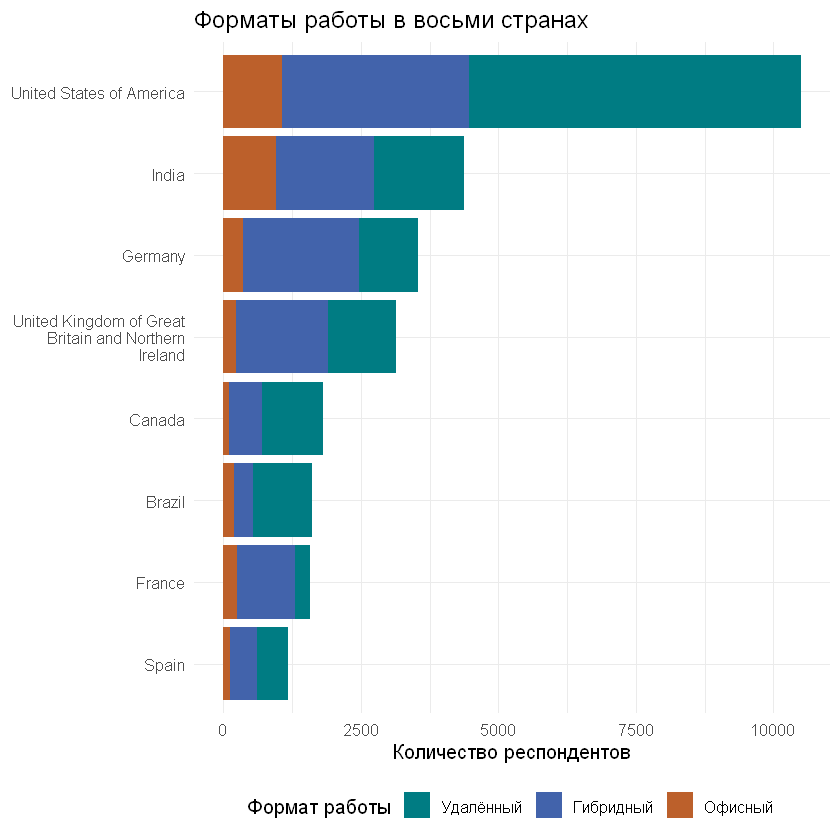

In [6]:
country_counts <- country_data |>
  count(country, format, name = "responses")

stopifnot(sum(country_counts$responses) == nrow(country_data))

ggplot(country_counts, aes(x = responses, y = factor(country, levels = rev(levels(country))), fill = format)) +
  geom_col() +
  scale_fill_manual(values = work_colours) +
  scale_y_discrete(labels = scales::label_wrap(26)) +
  labs(
    title = "Форматы работы в восьми странах",
    x = "Количество респондентов", y = NULL, fill = "Формат работы"
  ) +
  theme_minimal(base_size = 12) +
  theme(legend.position = "bottom")

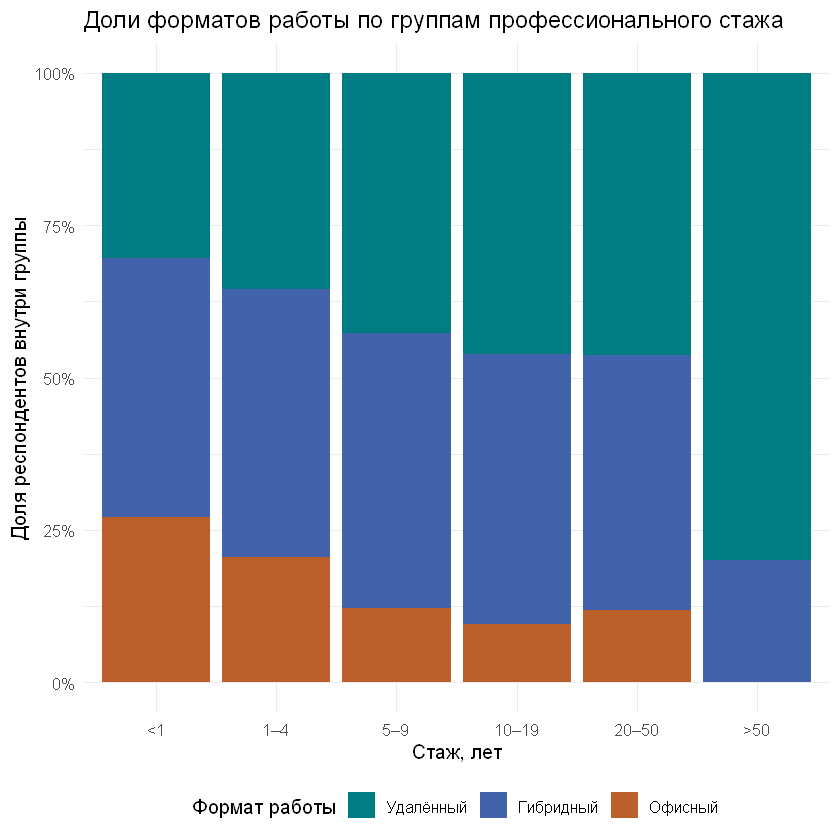

In [7]:
experience_shares <- experience_data |>
  count(experience, format, name = "responses") |>
  group_by(experience) |>
  mutate(share = responses / sum(responses)) |>
  ungroup()

share_check <- experience_shares |> group_by(experience) |> summarise(total = sum(share))
stopifnot(all(abs(share_check$total - 1) < 1e-12))

ggplot(experience_shares, aes(x = experience, y = share, fill = format)) +
  geom_col() +
  scale_fill_manual(values = work_colours) +
  scale_y_continuous(labels = function(values) paste0(round(100 * values), '%')) +
  labs(
    title = "Доли форматов работы по группам профессионального стажа",
    x = "Стаж, лет", y = "Доля респондентов внутри группы", fill = "Формат работы"
  ) +
  theme_minimal(base_size = 12) +
  theme(legend.position = "bottom")

## 5. Результаты и вывод

Таблица ниже показывает самый частый формат работы среди участников с полной занятостью и максимальную долю полностью удалённой работы по стажу. Размеры групп на первом графике различаются, поэтому их структуру нужно сравнивать по долям. В группе со стажем свыше 50 лет всего 10 анкет, поэтому её максимальная доля удалённой работы основана на небольшом числе наблюдений. Выводы описывают ответы участников опроса. Состав опроса по странам и стажу не позволяет оценить доли всех разработчиков в этих странах.

In [8]:
workers |>
  count(format, sort = TRUE, name = "responses") |>
  mutate(share_percent = round(100 * responses / sum(responses), 1L))

experience_shares |>
  filter(format == "Удалённый") |>
  slice_max(share, with_ties = TRUE) |>
  transmute(
    experience, remote_responses = responses,
    group_responses = round(responses / share),
    share_percent = round(100 * share, 1L)
  )

format,responses,share_percent
<fct>,<int>,<dbl>
Гибридный,21585,43.9
Удалённый,20022,40.7
Офисный,7581,15.4


experience,remote_responses,group_responses,share_percent
<fct>,<int>,<dbl>,<dbl>
>50,8,10,80
